In [2]:
import numpy as np
import pandas as pd
import prince
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd, numpy as np, prince

from scipy.cluster.hierarchy import linkage, fcluster


from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [3]:
raw = pd.read_csv(r"C:\Users\ugniu\PycharmProjects\Unsupervised  learning\Data\Processed\mental_health_cleaned_MCA.csv")

#this ensures there are no missing values
raw = raw.fillna("No answer")
raw = raw.dropna()

SE   = "Are you self-employed?"
PREV = "Do you have previous employers?"

In [4]:

#creating a separate column for the groups
raw["group"] = np.select(
    [(raw[SE] == 1) & (raw[PREV] == 0),
     raw[SE] == 1,
     raw[PREV] == 0],
    ["Self-employed + no prev. employer",
     "Self-employed",
     "No previous employer"],
    default="Employed with prev. employers (core)",
)

print(raw["group"].value_counts())

group
Employed with prev. employers (core)    1011
Self-employed                            249
No previous employer                     131
Self-employed + no prev. employer         37
Name: count, dtype: int64


In [5]:
X = raw.drop(columns="group").astype(str)    # categories must be text,

mca = prince.MCA(n_components=10, random_state=42).fit(X)

coords = mca.row_coordinates(X)                # one row per respondent
coords = coords.iloc[:, :2]                    # keep axes 1 and 2
coords.columns = ["axis1", "axis2"]
coords["group"] = raw["group"].values



In [6]:
def share_explained(values, groups):
    group_mean = values.groupby(groups).transform("mean")
    return 1 - ((values - group_mean) ** 2).sum() / ((values - values.mean()) ** 2).sum()

e1 = share_explained(coords["axis1"], coords["group"])
e2 = share_explained(coords["axis2"], coords["group"])
print(f"Groups explain {e1:.0%} of axis 1 and {e2:.0%} of axis 2")

Groups explain 100% of axis 1 and 98% of axis 2


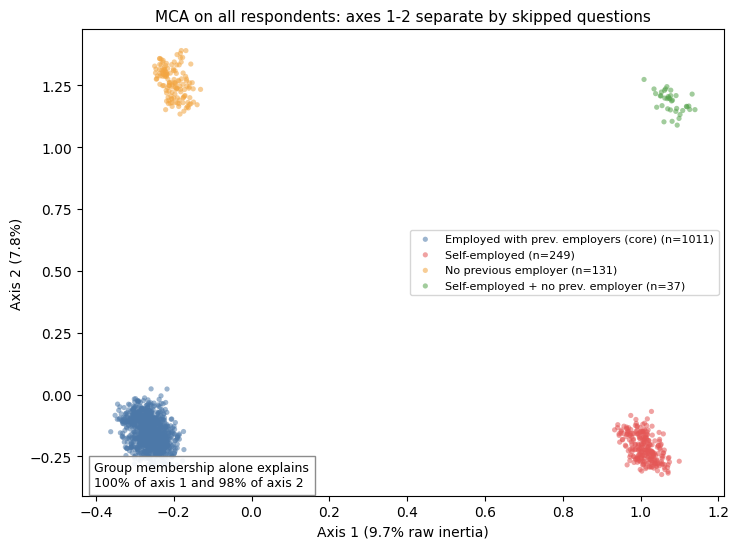

In [7]:
eig   = np.array(mca.eigenvalues_)
total = mca.total_inertia_

colors = {
    "Employed with prev. employers (core)": "#4C78A8",
    "Self-employed": "#E45756",
    "No previous employer": "#F2A541",
    "Self-employed + no prev. employer": "#54A24B",
}

fig, ax = plt.subplots(figsize=(7.5, 5.6))
for g, col in colors.items():
    sub = coords[coords["group"] == g]
    ax.scatter(sub["axis1"], sub["axis2"], s=14, alpha=0.55, c=col,
               label=f"{g} (n={len(sub)})", edgecolors="none")

ax.set_title("MCA on all respondents: axes 1-2 separate by skipped questions", fontsize=11)
ax.set_xlabel(f"Axis 1 ({eig[0]/total:.1%} raw inertia)")
ax.set_ylabel(f"Axis 2 ({eig[1]/total:.1%})")
ax.legend(fontsize=8, loc="center right")
ax.text(0.02, 0.02, f"Group membership alone explains\n{e1:.0%} of axis 1 and {e2:.0%} of axis 2",
        transform=ax.transAxes, fontsize=9, bbox=dict(fc="white", ec="grey", alpha=0.9))
plt.tight_layout()
plt.show()



In [8]:
# keep employed respondents with previous employers, then drop the helper columns
df = raw[(raw[SE] == 0) & (raw[PREV] == 1)].copy()
df = df.drop(columns=[SE, PREV, "group"])
print(df.shape)

(1011, 57)


In [9]:
#checking the column structure
for column in df.columns:
    print("\n" + "=" * 80)
    # show only 10 values
    print(df[column].value_counts(dropna=False).head(10))
    print(f"n_unique: {df[column].nunique()}")





How many employees does your company or organization have?
26-100            261
100-500           227
More than 1000    217
6-25              182
500-1000           73
1-5                51
Name: count, dtype: int64
n_unique: 6

Is your employer primarily a tech company/organization?
Yes    784
No     227
Name: count, dtype: int64
n_unique: 2

Does your employer provide mental health benefits as part of healthcare coverage?
Yes                                477
I don't know                       283
No                                 184
Not eligible for coverage / N/A     67
Name: count, dtype: int64
n_unique: 4

Do you know the options for mental health care available under your employer-provided coverage?
No               309
I am not sure    307
Yes              279
No answer        116
Name: count, dtype: int64
n_unique: 4

Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?
No              713
Y

In [10]:

#Applying the MCA

# transforming the variables into strings
X = df.astype(str)
mca = prince.MCA(n_components=20, random_state=42)
mca.fit(X)
coords = mca.row_coordinates(X).to_numpy()

#prints out how much variance each dimensioin carries
print(mca.eigenvalues_)

[0.13685118 0.10372794 0.0632397  0.06033224 0.05045503 0.04582199
 0.03863968 0.03624269 0.03493366 0.03474529 0.03247853 0.03165585
 0.03036688 0.02945641 0.02867584 0.02842336 0.02766821 0.02727762
 0.02654936 0.02607611]


In [11]:
#conversion to string, asserting there are no redundant columns after manipulation
X = df.astype(str)
assert not {"cluster", "group"} & set(X.columns), "label column in MCA input"

#applying mca
mca = prince.MCA(n_components=100, random_state=42).fit(X)
coords_all = mca.row_coordinates(X).to_numpy()

#Because MCA variances are often very low, we use the  benzecri correction
#So the real number of explained vsariance lies between these two bounds

Q = X.shape[1]
eig = np.array(mca.eigenvalues_)
lam = eig[eig > 1/Q]
print("axes above 1/Q:", len(lam), "of", len(eig))      # must be below 100


mod = ((Q/(Q-1)) * (lam - 1/Q))**2
rate = mod / mod.sum()
print("Benzécri cumulative %:", np.round(np.cumsum(rate)[:8] * 100, 1))

axes above 1/Q: 47 of 100
Benzécri cumulative %: [46.3 70.5 77.3 83.3 86.8 89.4 90.9 92. ]


          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.137         5.91%                      5.91%
1              0.104         4.48%                     10.39%
2              0.063         2.73%                     13.12%
3              0.060         2.61%                     15.72%
4              0.050         2.18%                     17.90%
5              0.046         1.98%                     19.88%
6              0.039         1.67%                     21.55%
7              0.036         1.57%                     23.12%
8              0.035         1.51%                     24.62%
9              0.035         1.50%                     26.12%


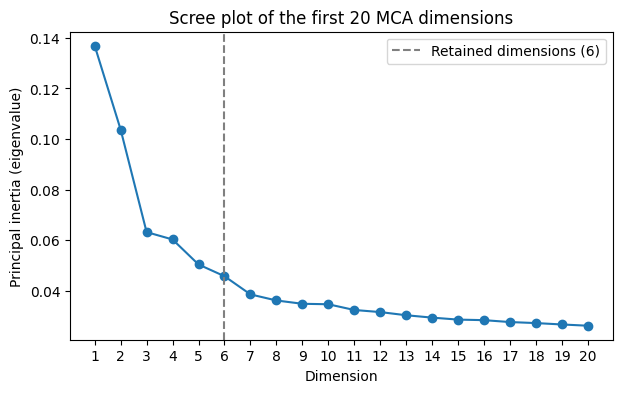

In [12]:
Q = X.shape[1]
eig = np.array(mca.eigenvalues_)

print(mca.eigenvalues_summary.head(10))

plt.figure(figsize=(7, 4))
plt.plot(range(1, 21), eig[:20], "o-")
plt.axvline(6, ls="--", c="grey", label="Retained dimensions (6)")
plt.xticks(range(1, 21))
plt.xlabel("Dimension")
plt.ylabel("Principal inertia (eigenvalue)")
plt.title("Scree plot of the first 20 MCA dimensions")
plt.legend()
#to save the picture
plt.savefig("scree_plot.png", dpi=300, bbox_inches="tight")

plt.show()



In [13]:
cc = mca.column_contributions_.iloc[:, :6].copy()
cc["variable"] = [str(i).rsplit("__", 1)[0] for i in cc.index]
by_var = cc.groupby("variable").sum() * 100

for a in range(6):
    print(f"\nAxis {a+1}: top variables (% contribution)")
    print(by_var[a].sort_values(ascending=False).head(6).round(1).to_string())


Axis 1: top variables (% contribution)
variable
Have you been diagnosed with a mental health condition by a medical professional?                                       7.5
If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?    7.4
Have you had a mental health disorder in the past?                                                                      7.1
Have you ever sought treatment for a mental health issue from a mental health professional?                             6.8
If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?        6.7
Do you currently have a mental health disorder?                                                                         6.3

Axis 2: top variables (% contribution)
variable
Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?                                    6.9
Would you feel comfortab

In [14]:
cc = mca.column_contributions_.iloc[:, :6].copy()

# Group categories by their original variable
cc["variable"] = [str(i).rsplit("__", 1)[0] for i in cc.index]
by_var = cc.groupby("variable").sum() * 100

# Category-level contributions in percentage
cc_cat = mca.column_contributions_.iloc[:, :6] * 100

for a in range(6):
    dim = a + 1
    col = cc.columns[a] if a < len(cc.columns) else a

    print(f"\n{'='*50}")
    print(f"Axis {dim}: Top variables (% contribution)")
    print(by_var.iloc[:, a].sort_values(ascending=False).head(6).round(1).to_string())

    print(f"\nAxis {dim}: Top answer categories (% contribution)")
    print(
        cc_cat.iloc[:, a]
        .sort_values(ascending=False)
        .head(10)
        .round(1)
        .to_string()
    )


Axis 1: Top variables (% contribution)
variable
Have you been diagnosed with a mental health condition by a medical professional?                                       7.5
If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?    7.4
Have you had a mental health disorder in the past?                                                                      7.1
Have you ever sought treatment for a mental health issue from a mental health professional?                             6.8
If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?        6.7
Do you currently have a mental health disorder?                                                                         6.3

Axis 1: Top answer categories (% contribution)
If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?__Not applicable to me    4.4
Have you ever

In [15]:
freq = {f"{c}__{v}": n / len(X) for c in X.columns for v, n in X[c].value_counts().items()}
cc = mca.column_coordinates(X)
cc["freq"] = cc.index.map(freq)
print("unmatched:", cc["freq"].isna().sum())          # should be 0
common = cc[cc["freq"] >= 0.03]

for dim in range(6):
    d = common.iloc[:, dim].sort_values()
    print(f"\nDim {dim+1} NEGATIVE:", [i for i in d.index[:4]])
    print(f"Dim {dim+1} POSITIVE:", [i for i in d.index[-4:]])

unmatched: 0

Dim 1 NEGATIVE: ['condition_PTSD__1', 'Do you think that discussing a physical health issue with your employer would have negative consequences?__Yes', 'Do you feel that being identified as a person with a mental health issue would hurt your career?__Yes, it has', 'Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?__Yes, I experienced']
Dim 1 POSITIVE: ['If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?__Not applicable to me', 'Have you had a mental health disorder in the past?__No', 'How willing would you be to share with friends and family that you have a mental illness?__Not applicable to me (I do not have a mental illness)', 'If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?__Not applicable to me']

Dim 2 NEGATIVE: ['How willing would you be to share wit

In [16]:
mca.eigenvalues_summary.head(6)


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.137,5.91%,5.91%
1,0.104,4.48%,10.39%
2,0.063,2.73%,13.12%
3,0.060,2.61%,15.72%
4,0.050,2.18%,17.90%
5,0.046,1.98%,19.88%


In [17]:
np.round(np.cumsum(rate)[:6] * 100, 1)

array([46.3, 70.5, 77.3, 83.3, 86.8, 89.4])

In [18]:
N_AXES = 6
coords = coords_all[:, :N_AXES]
Z = linkage(coords, method="ward")

In [19]:
print("Merge distance for k", np.round(Z[-10:, 2][::-1], 2))
print()
for k in range(2, 9):
    lab = fcluster(Z, t=k, criterion="maxclust")
    sizes = np.bincount(lab)[1:]
    print(k, "silhouette:", round(silhouette_score(coords, lab), 3), "sizes:", sizes)

Merge distance for k [12.9  10.02  6.82  6.31  6.08  5.12  5.03  4.99  4.93  3.92]

2 silhouette: 0.175 sizes: [348 663]
3 silhouette: 0.154 sizes: [348 310 353]
4 silhouette: 0.126 sizes: [348 310 140 213]
5 silhouette: 0.129 sizes: [ 48 300 310 140 213]
6 silhouette: 0.122 sizes: [ 48 300 168 142 140 213]
7 silhouette: 0.12 sizes: [ 48 300 168 142 140 108 105]
8 silhouette: 0.105 sizes: [ 48 161 139 168 142 140 108 105]


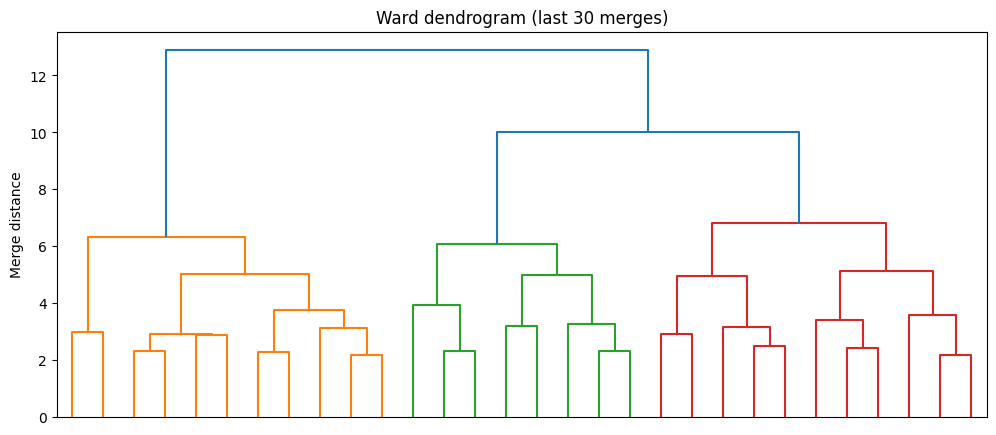

In [20]:
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
plt.title("Ward dendrogram (last 30 merges)")
plt.ylabel("Merge distance")
plt.show()

In [21]:
K = 3
labels = fcluster(Z, t=K, criterion="maxclust")

df_clustered = df.copy()
df_clustered["cluster"] = labels
print(df_clustered["cluster"].value_counts().sort_index())

cluster
1    348
2    310
3    353
Name: count, dtype: int64


In [22]:
dims = pd.DataFrame(coords, columns=[f"Dim {i}" for i in range(1, N_AXES + 1)])
dims["cluster"] = labels
print(dims.groupby("cluster").mean().round(2))

         Dim 1  Dim 2  Dim 3  Dim 4  Dim 5  Dim 6
cluster                                          
1         0.39  -0.00  -0.02   0.02  -0.03   0.00
2        -0.21   0.29  -0.01  -0.03   0.03   0.04
3        -0.21  -0.25   0.03   0.01   0.00  -0.04


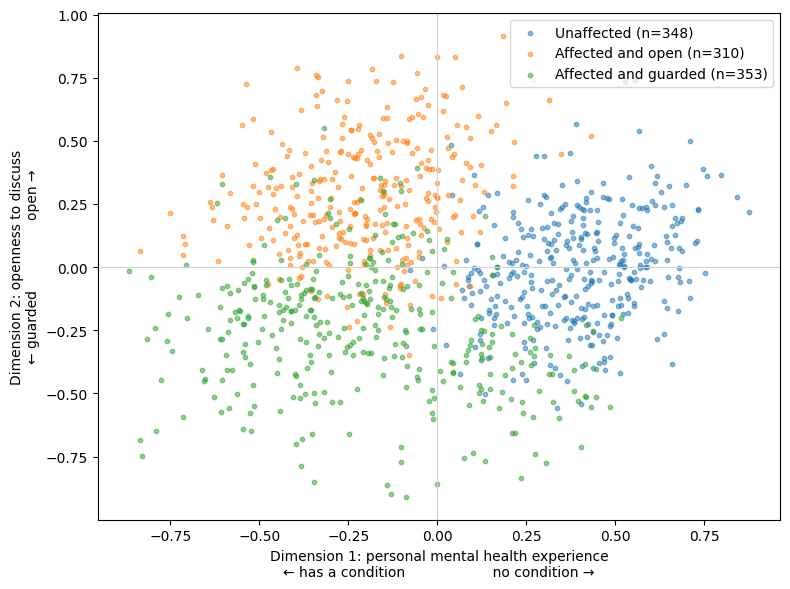

In [23]:
names = {1: "Unaffected", 2: "Affected and open", 3: "Affected and guarded"}   # your names

fig, ax = plt.subplots(figsize=(8, 6))
for k in sorted(set(labels)):
    m = labels == k
    ax.scatter(coords[m, 0], coords[m, 1], s=10, alpha=0.5, label=f"{names[k]} (n={m.sum()})")

ax.axhline(0, c="lightgrey", lw=0.8); ax.axvline(0, c="lightgrey", lw=0.8)
ax.set_xlabel("Dimension 1: personal mental health experience\n← has a condition                    no condition →")
ax.set_ylabel("Dimension 2: openness to discuss\n← guarded                open →")
ax.legend()
plt.tight_layout()
plt.savefig("clusters_dims.png", dpi=300, bbox_inches="tight")   # before show()
plt.show()

In [37]:
#Profiling columns!
key_responses = {
    "Professional diagnosis": {"column": "Have you been diagnosed with a mental health condition by a medical professional?","response":"Yes"},

    "Sought treatment":{"column":"Have you ever sought treatment for a mental health issue from a mental health professional?", "response": 1 },

    "Not comfortable sharing with supervisor": { "column": "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?","response": "No"},

    "Not comfortable sharing with coworkers": {"column": "Would you feel comfortable discussing a mental health disorder with your coworkers?","response": "No"},

    "Negative consequences discussing with employer": {"column": "Do you think that discussing a mental health disorder with your employer would have negative consequences?","response": "Yes"},

    "Maybe Negative consequences discussing with employer": {"column": "Do you think that discussing a mental health disorder with your employer would have negative consequences?","response": "Maybe"},


    "Perceived career harm": {"column": "Do you feel that being identified as a person with a mental health issue would hurt your career?","response": "Yes, I think it would"},

    "Current employer provides benefits": {"column": "Does your employer provide mental health benefits as part of healthcare coverage?","response": "Yes"},

    "Current employer offers resources to learn": {"column": "Does your employer offer resources to learn more about mental health concerns and options for seeking help?","response": "Yes"},

    "Employer has not officially addressed MH issues": {"column": "Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?", "response": "No" },

    "Is aware of offered benefits": {"column": "Do you know the options for mental health care available under your employer-provided coverage?", "response": "Yes"},

    "Medical leave is very difficult": {
    "column": "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",
    "response": "Very difficult"},

    "Medical leave is difficult": {
    "column": "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",
    "response": "Somewhat difficult"},

    "Age between 26-35" : {"column": "What is your age?", "response": "26-35" },
    "Age between 36-45" : {"column": "What is your age?", "response": "36-45" },
    "Age between 18-25" : {"column": "What is your age?", "response": "18-25" },
    "Age between 46+" : {"column": "What is your age?", "response": "46+" }
}



summary = {}

for label, item in key_responses.items():
    col = item["column"]
    response = item["response"]

    if col not in df_clustered.columns:
        continue

    summary[label] = (
        df_clustered.assign(
            selected=df_clustered[col].eq(response)
        )
        .groupby("cluster")["selected"]
        .mean()
        .mul(100)
        .round(1)
    )

summary_df = pd.DataFrame(summary).T
print(summary_df.to_string())


cluster                                                  1     2     3
Professional diagnosis                                 4.6  90.3  61.5
Sought treatment                                      16.4  94.8  69.4
Not comfortable sharing with supervisor               14.9  12.3  54.1
Not comfortable sharing with coworkers                23.3  16.1  58.6
Negative consequences discussing with employer         4.3   7.7  42.5
Maybe Negative consequences discussing with employer  39.7  41.0  45.3
Perceived career harm                                 26.7  24.8  60.1
Current employer provides benefits                    38.8  70.0  35.4
Current employer offers resources                     22.7  42.6  15.3
Employer has not officially addressed MH issues       66.1  59.4  84.7
Is aware of offered benefits                          16.4  49.4  19.5
Medical leave is very difficult                        2.3   3.2  23.5
Medical leave is difficult                             9.2  15.2  27.8
Age be